# Derwent estuary erosion susceptibility: CVI and fuzzy overlay

> Search this notebook for **EDIT** to find everything you need to change, and **ASSUMPTION** to find choices you must justify in your methods.
> Write your own explanation under each heading.

## 1. Set-up

In [93]:
from pathlib import Path
import numpy as np
import geopandas as gpd
import shapely
from shapely.geometry import box, Point, LineString
import rasterio
from rasterio.merge import merge
from rasterio.features import rasterize
from rasterio.transform import from_origin
from rasterio.enums import Resampling
import rioxarray as rxr
import xarray as xr
from scipy.spatial import cKDTree
from scipy.stats import spearmanr
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import leafmap

inpath = Path(r"C:\AT3\inpath")
outpath = Path(r"C:\AT3\outpath")

bounding_box = inpath / "Bounding_Box.shp"          # rectangle around the whole Derwent estuary
dem_folder = inpath / "dem_tiles_extent"                   # folder holding the DEM tiles
wind_file = inpath / "data.grib"                    # ERA5 wind data
coast_file = inpath / "list_coastline_statewide.shp"
geology_file = inpath / "geology_units25kk.shp"
land_file = inpath / "Derwent_land_cover_MGA2020.shp"       # must be a land OUTLINE polygon, not land-cover classes
surge_folder = {
    "2010": inpath / "2010_surge",
    "2100": inpath / "2100_surge",
}

# ---------- settings  ----------
TARGET_CRS = "EPSG:7855"
GRID_RES = 10
SHORE_SPACING = 200
LAND_SIMPLIFY = 50
RAY_CAP = 30_000
BEARINGS = np.arange(0, 360, 22.5)
MIN_WIND = 5
DIST_MAX = 100
SLOPE_MAX = 10
RATE_MAX = 0.5
DEA_MAX_DIST = 50
GAMMA = 0.9
FLOOR = 0.05

In [94]:
import sys
print(sys.executable)
try:
    import cfgrib
    print("cfgrib", cfgrib.__version__)
except Exception as e:
    print("cfgrib import failed:", repr(e))
try:
    import eccodes
    print("eccodes", eccodes.__version__)
except Exception as e:
    print("eccodes import failed:", repr(e))
import xarray
print("xarray", xarray.__version__)

import os
env = r"C:\Users\fjcal\miniconda3\envs\kgg375_erosionmodel_at3"
os.environ["PATH"] = env + r"\Library\bin;" + env + r"\Library\mingw-w64\bin;" + os.environ["PATH"]
os.environ["ECCODES_DIR"] = env + r"\Library"
os.add_dll_directory(env + r"\Library\bin")


c:\Users\fjcal\miniconda3\envs\kgg375_erosionmodel_at3\python.exe
cfgrib 0.9.15.1
eccodes 2.49.0
xarray 2026.9.0


<AddedDllDirectory('C:\\Users\\fjcal\\miniconda3\\envs\\kgg375_erosionmodel_at3\\Library\\bin')>

In [95]:
# Turn the bounding box file into a clean rectangle in EPSG:7855
bounds = gpd.read_file(bounding_box).to_crs(TARGET_CRS).total_bounds
area = gpd.GeoSeries([box(*bounds)], crs=TARGET_CRS)
print([round(b) for b in bounds])      # should be metres (e.g. 6 digits), not degrees

[522319, 5232484, 537562, 5258148]


## 2. Stitch the DEM tiles

In [96]:
from rasterio.warp import reproject

tile_files = sorted(dem_folder.glob("*.tif"))
print(len(tile_files), "tiles")

with rasterio.open(tile_files[0]) as src:
    tile_crs = src.crs

# the output grid: the bounding box at GRID_RES, in the tiles' CRS
minx, miny, maxx, maxy = area.to_crs(tile_crs).total_bounds
width = int(np.ceil((maxx - minx) / GRID_RES))
height = int(np.ceil((maxy - miny) / GRID_RES))
dem_transform = from_origin(minx, maxy, GRID_RES, GRID_RES)
print("output grid:", height, "rows x", width, "cols")

mosaic = np.full((height, width), np.nan, dtype="float32")

for i, f in enumerate(tile_files):
    with rasterio.open(f) as src:                       # one tile open at a time
        tmp = np.full((height, width), np.nan, dtype="float32")
        reproject(source=rasterio.band(src, 1), destination=tmp,
                  dst_transform=dem_transform, dst_crs=tile_crs,
                  src_nodata=src.nodata, dst_nodata=np.nan,
                  resampling=Resampling.average)        # averages the 1 m cells into 25 m
    ok = np.isfinite(tmp)
    mosaic[ok] = tmp[ok]                                # paste this tile in
    if i % 20 == 0:
        print("done", i + 1, "of", len(tile_files))

with rasterio.open(outpath / "DEM_raw.tif", "w", driver="GTiff", count=1,
                   height=height, width=width, dtype="float32",
                   crs=tile_crs, transform=dem_transform, nodata=np.nan,
                   compress="deflate") as dst:
    dst.write(mosaic, 1)

dem = rxr.open_rasterio(outpath / "DEM_raw.tif", masked=True)
dem = dem.rio.reproject(TARGET_CRS, resolution=GRID_RES)
dem.rio.to_raster(outpath / f"DEM_{GRID_RES}m.tif", compress="deflate")

497 tiles
output grid: 2567 rows x 1525 cols
done 1 of 497
done 21 of 497
done 41 of 497
done 61 of 497
done 81 of 497
done 101 of 497
done 121 of 497
done 141 of 497
done 161 of 497
done 181 of 497
done 201 of 497
done 221 of 497
done 241 of 497
done 261 of 497
done 281 of 497
done 301 of 497
done 321 of 497
done 341 of 497
done 361 of 497
done 381 of 497
done 401 of 497
done 421 of 497
done 441 of 497
done 461 of 497
done 481 of 497


## 3. Reproject and clip the other layers

In [97]:
def prepare(file, out, pad=0, layer=None):
    # read only the features near the bounding box, reproject, then clip
    file_crs = gpd.read_file(file, layer=layer, rows=1).crs
    window = area.buffer(pad, join_style="mitre")
    gdf = gpd.read_file(file, layer=layer, bbox=tuple(window.to_crs(file_crs).total_bounds))
    gdf = gdf.to_crs(TARGET_CRS)
    gdf.geometry = gdf.geometry.make_valid()
    gdf = gpd.clip(gdf, window)
    gdf = gdf.rename(columns={"fid": "fid_orig"})      # GeoPackage reserves 'fid' for its own row ID
    gdf.to_file(out, driver="GPKG")
    return gdf


coast_gdf = prepare(coast_file, outpath / "coastline.gpkg", pad=500)               # small margin avoids edge effects
geology_gdf = prepare(geology_file, outpath / "geology.gpkg")
land_gdf = prepare(land_file, outpath / "land.gpkg", pad=RAY_CAP)                  # extra margin for the rays

## 4. Wave exposure: fetch

In [98]:
# one land shape, simplified so the rays run faster
land = shapely.union_all(land_gdf.geometry.values).simplify(LAND_SIMPLIFY)
shapely.prepare(land)
polys = land_gdf.geometry.explode(index_parts=False)
polys = polys[polys.geom_type == "Polygon"]            # drop stray lines/points left by clip and make_valid
land = polys.union_all().simplify(LAND_SIMPLIFY)       # one clean (Multi)Polygon
shapely.prepare(land)                                  # speeds up the ray tests later
print(land.geom_type, "| empty:", land.is_empty, "| boundary empty:", land.boundary.is_empty)

# a point along the coastline every SHORE_SPACING metres inside the bounding box
coast = shapely.line_merge(shapely.union_all(coast_gdf.geometry.values))
pts = np.array([part.interpolate(d) for part in shapely.get_parts(coast)
                for d in np.arange(0, part.length, SHORE_SPACING)])
pts = pts[shapely.contains(area.iloc[0], pts)]
print(len(pts), "shoreline points")

# move each point onto the edge of the land polygon
snapped = shapely.get_point(shapely.shortest_line(pts, land.boundary), -1)

MultiPolygon | empty: False | boundary empty: False
1826 shoreline points


In [99]:
def ray_length(pt, bearing):
    # open-water distance from pt toward the bearing, until the ray hits land
    a = np.radians(bearing)
    start = Point(pt.x + np.sin(a), pt.y + np.cos(a))       # 1 m offshore
    if land.contains(start):
        return 0.0                                          # the wind direction points at land
    end = Point(pt.x + RAY_CAP * np.sin(a), pt.y + RAY_CAP * np.cos(a))
    hit = LineString([start, end]).intersection(land)
    return RAY_CAP if hit.is_empty else min(pt.distance(hit), RAY_CAP)

bad = [i for i, p in enumerate(snapped) if p is None or p.is_empty]
print(len(snapped), "points,", len(bad), "empty")

snapped = [p for p in snapped if p is not None and not p.is_empty]
print(len(snapped), "points kept")

# this can take several minutes for a whole estuary
fetch = np.array([[ray_length(p, b) for b in BEARINGS] for p in snapped])   # one row per point, one column per bearing



1826 points, 0 empty
1826 points kept


## 5. Wind weights from the GRIB file

In [100]:
# needs: conda install -c conda-forge cfgrib eccodes
wind = xr.open_dataset(wind_file, engine="cfgrib")

# one wind record for the whole estuary: the grid cell nearest the centre of the study area
site = area.to_crs(4326).iloc[0].centroid
wind = wind.sel(latitude=site.y, longitude=site.x, method="nearest")

u, v = wind["u10"].values, wind["v10"].values
speed = np.hypot(u, v)
direction_from = (270 - np.degrees(np.arctan2(v, u))) % 360      # direction the wind blows FROM
sector = ((direction_from + 11.25) // 22.5 % 16).astype(int)     # 0 = north, 1 = 22.5 degrees, ...

# count winds from each direction, ignoring light winds that make negligible waves
wind_weights = np.bincount(sector[speed > MIN_WIND], minlength=16)
print(np.round(wind_weights / wind_weights.sum(), 3))

[0.038 0.025 0.027 0.019 0.008 0.008 0.005 0.014 0.038 0.069 0.112 0.137
 0.168 0.183 0.106 0.044]


In [101]:
# combine the 16 directions into one exposure value per shoreline point
fetch_w = (fetch * wind_weights).sum(axis=1) / wind_weights.sum()
shore = gpd.GeoDataFrame({"fetch": fetch_w}, geometry=snapped, crs=TARGET_CRS)
shore.to_file(outpath / "fetch_points.gpkg", driver="GPKG")

# the grid every factor layer will share
minx, miny, maxx, maxy = bounds
xs = np.arange(minx + GRID_RES / 2, maxx, GRID_RES)
ys = np.arange(maxy - GRID_RES / 2, miny, -GRID_RES)
xx, yy = np.meshgrid(xs, ys)
cells = np.c_[xx.ravel(), yy.ravel()]
transform = from_origin(minx, maxy, GRID_RES, GRID_RES)


def to_da(arr):
    return xr.DataArray(arr.astype("float32"), coords={"y": ys, "x": xs}, dims=("y", "x")).rio.write_crs(TARGET_CRS)

# give every cell the value of its nearest shoreline point
_, nearest = cKDTree(np.c_[shapely.get_x(snapped), shapely.get_y(snapped)]).query(cells)
fetch_grid = fetch_w[nearest].reshape(xx.shape)
to_da(fetch_grid).rio.to_raster(outpath / "fetch_exposure.tif")

## 6. Factor layers (each scaled 0 to 1, higher = more vulnerable)

In [102]:
from scipy.ndimage import distance_transform_edt

# 1. distance to shoreline: closer = more vulnerable
dense = np.array([part.interpolate(d) for part in shapely.get_parts(coast)
                  for d in np.arange(0, part.length, GRID_RES)])
dist, _ = cKDTree(np.c_[shapely.get_x(dense), shapely.get_y(dense)]).query(cells)
dist_grid = dist.reshape(xx.shape)
dist_m = 1 - np.clip(dist_grid / DIST_MAX, 0, 1)

# 2. wave exposure: rescale wind-weighted fetch to 0-1
exposure_m = (fetch_grid - fetch_grid.min()) / (fetch_grid.max() - fetch_grid.min())

# 3. slope from the DEM (CVI convention: flatter ground = more vulnerable)
dem_grid = dem.rio.reproject_match(to_da(fetch_grid), resampling=Resampling.average).squeeze().values
dzdy, dzdx = np.gradient(dem_grid, GRID_RES)
slope = np.degrees(np.arctan(np.hypot(dzdx, dzdy)))

# fill small DEM gaps (up to 4 cells = 100 m) from the nearest valid cell; larger gaps stay empty
gap_dist, nearest = distance_transform_edt(np.isnan(slope), return_indices=True)
slope = np.where(gap_dist <= 10, slope[tuple(nearest)], np.nan)
slope_m = 1 - np.clip(slope / SLOPE_MAX, 0, 1)

# the analysed zone: land cells within DIST_MAX of the shoreline
# full-detail land polygon (not the 50 m simplified one) plus a small margin for cells on the coast edge
land_full = land_gdf.geometry.union_all()
LAND_MARGIN = 10        # m
land_zone = rasterize([(land_full.buffer(LAND_MARGIN), 1)], out_shape=fetch_grid.shape,
                      transform=transform, fill=0).astype(bool)
zone = land_zone & (dist_grid <= DIST_MAX)


In [103]:
# 4. geology: rank each unit from 1 (very resistant) to 5 (very erodible)
# Ranks follow rock strength and consolidation, supported by the lithology erodibility index table:
# unconsolidated sediments have by far the highest index (~3.2) and consolidated rocks sit at ~1.0-1.5.
# ASSUMPTION: every Quaternary deposit is rank 5 (loose, young sediment).
# Paste or edit descriptions below: one per line, no quotes or commas needed.

group1 = """
Dolerite and related rocks
Inferred dolerite beneath soil or Cainozoic deposits.
Dolerite, fine grained (0.7 - 1.5 mm).
Granophyre and pegmatite.
Basaltic lava (nepheline hawaiite to olivine nephelinite) with abundant lherzolite xenoliths.
Basaltic lava (dominantly sodic hawaiite) and pyroclastics, with rare to locally abundant lherzolite xenoliths.
Inferred basalt beneath soil or Cainozoic deposits.
Transitional olivine basalt.
Basaltic lava (nepheline mugearite to nepheline benmoreite), locally interbedded with pyroclastics.
Mugearite.
Basaltic lava (sodic nepheline hawaiite to nepheline mugearite) locally with minor agglomerate and small lherzolite xenoliths.
Basalt.
Alkali basalt.
Supra-basalt moderately lithified conglomerate  with at places ferruginous cement or interbedded sandstone, clasts of well rounded cobbles and pebbles of quartz, quartzite, hornfels and traces of silicified wood, recycled Lower Parmeener lonestones, Tert
"""

group2 = """
Cliff forming massive bioturbated to homogeneous moderately well-sorted fine- to coarse-grained marine feldspathic quartz sandstone with thin layers containing abundant pebbles or cobbles (Risdon Sandstone).
Freshwater cross-bedded arkose to quartzose sandstone and micaceous siltstone.
Interbedded cross-bedded white quartzose sandstone, quartz-rich lithic sandstone, siltstone and mudstone.
Coarse-grained sandstone to granule sandstone, pebbles in some areas.
Freshwater predominantly cross-bedded quartzose to feldspathic sandstone commonly with overturned cross-bedding, subordinate siltstone with sparse plant and vertebrate fossils (Knocklofty Formation).
Dominantly freshwater cross-bedded quartzose sandstone, micaceous siltstone and mudstone (correlate of Ross Sandstone).
Unit Pua (5085) contact metamorphosed by Jurassic dolerite.
Unit Pum (5084 ) contact metamorphosed by Jurassic dolerite.
Unit Pud, contact metamorphosed by Jurassic dolerite.
Unit Puc, contact metamorphosed by Jurassic dolerite.
"""

group3 = """
Undifferentiated Parmeener Supergroup rocks.
Undifferentiated Permo-Carboniferous sediments.
Dark grey marine mudstone and siltstone with upper fossiliferous part rich in the brachiopod Cancrinella (Hickman Formation).
Paralic, massive, laminated, flaser-bedded or ripple cross-laminated micaceous sandstone and siltstone, thin beds of wavy- or cross-bedded sandstone and pebbly granule sandstone, marine bioturbated intervals with pebbles and rare shell fossils (Faulkner Formation).
Sparsely to richly fossiliferous marine siltstone, mudstone, sandstone and impure limestone with lonestones (correlate of Bundella Formation).
Uniform, poorly-bedded, coarsely fretting grey marine siltstone with sparse lonestones and probable glendonite moulds (correlate of Woody Island Siltstone).
Undifferentiated generally unfossiliferous glaciomarine fissile and non-fissile siltstone and silty sandstone with lonestones (Abels Bay Formation, Malbina Formation, Risdon Sandstone).
Undifferentiated fossiliferous glaciomarine sandstone, siltstone and limestone (Deep Bay Formation, Berriedale Limestone, Nassau Siltstone and Rayner Sandstone).
Generally unfossiliferous glaciomarine interbedded non-fissile and fissile siltstone and silty sandstone, with common bioturbation and lonestones.
Richly fossiliferous glaciomarine grey bioclastic to argillaceous limestone, calcareous siltstone and rare metabentonite (Berriedale Limestone); lower fossiliferous siltstone and calcareous siltstone (Nassau Formation); basal pebbly sandstone (Rayner Sandstone).
Dominantly interbedded richly fossiliferous glaciomarine siltstone and sandstone and subordinate thin beds of granule sandstone, lonestones present, thin- to medium-bedded, commonly leached yellow-cream coloured (Deep Bay Formation).
Generally poorly fossiliferous interbedded glaciomarine fine- to medium-grained sandstone, fissile and non-fissile siltstone, lonestones and pebble-rich patches (Malbina Formation).
Thickly- to thinly-bedded volcanic lithic sandstone, siltstone, mudstone and coal seams, fossil plants on some horizons (New Town Coal Measures).
Interbedded yellow brown or grey carbonaceous siltstone, mudstone and thin to thick-bedded quartz-rich lithic arkosic sandstone.
Interbedded micaceous brown, red-purple, green and grey carbonaceous siltstone, shale and mudstone.
Predominantly interbedded siltstone shale and mudstone and planar-bedded, ripple cross-laminated or cross-bedded sandstone (Knocklofty Formation).
Predominantly interbedded red-purple, green, tan and grey micaceous siltstone and ripple cross-laminated, planar-bedded, or cross-bedded sandstone with sparse plants and vertebrate fossils (Poets Road Member).
Undifferentiated Upper Parmeener Supergroup rocks.
Undifferentiated volcaniclastic, quartz-rich lithic and quartzose sandstone, siltstone, mudstone, carbonaceous beds and coal seams.
"""

group4 = """
Silicastone and lag of silicastone.
Undifferentiated Cenozoic sediments.
Deposits of extremely weathered dolerite and Parmeener clasts pebble to small boulder size and with clayey matrix.
Supra-basalt moderately lithified conglomerate with ferruginous cement or interbedded sandstone.
Undifferentiated deposits with possible subsurface Tertiary basalt.
Dominantly poorly consolidated plastic clay, silty clay and sandy clay with minor pebbly layers and subordinate gravel.
Undifferentiated Tertiary.
Agglomerate and tuff.
Upper Freshwater Unit - consolidated fine- to medium-grained sandstone, siltstone, minor conglomerates and clay with Tertiary fossil flora.
Poorly-consolidated white siltstone, sandstone and claystone with Tertiary fossil flora.
Poorly-consolidated interbedded claystone, sandstone and pebble conglomerate (Tse).
Dominantly semiconsolidated silt and clay.
Travertine spring deposits with fossil plants and non-marine fauna, associated with basalt at Geilston Bay.
Sub-basalt very poorly consolidated olive brown and buff coloured plastic mudstone, siltstone and sandstone.
Poorly consolidated claystone with some horizons with lignitic material.
Sub-basalt or inferred sub-basalt very poorly consolidated, well-sorted sandstone, siltstone and claystone.
Dominantly non-marine sequences of gravel, sand, silt, clay and regolith.
Semiconsolidated, pebble to boulder grade gravels with clasts of dolerite, Parmeener Supergroup rocks and basalt.
Deposits of very large (>2 m) dolerite boulders in clay, and derived bouldery lag deposits.
Clay and gravelly clay with sparse to abundant dolerite boulders.
Poorly sorted boulder to pebble grade deposits with boulders up to 3 m length, clasts generally dominantly of dolerite.
Inferred dolerite boulder beds with possible shallow subsurface dolerite or Parmeener rock.
Poorly-sorted boulder to pebble grade deposits, clasts dominantly of Upper Parmeener sandstone.
Green to orange-brown sandy-clay contains pebbles and boulders mainly of Jurassic dolerite.
Dolerite boulders in light-brown clayey-gravel matrix.
Red sandy-silty clay with rare quartz pebbles, large dolerite boulders abundant in the lower part of this sequence.
Unit Tcbu, with abundant surficial dolerite boulders.
Poorly- consolidated  white siltstone, sandstone and claystone with Tertiary fossil flora.
"""

group5 = """
Undifferentiated fluviatile and swamp deposits of poorly consolidated to unconsolidated sand, clayey sand and silt.
Undifferentiated sand and gravel deposits.
Undifferentiated poorly-consolidated, piedmont, alluvial fan, alluvial terrace, raised beach lag and exhumed deposits containing pebbles or cobbles of dolerite or Parmeener derived rocks.
Alluvial gravel, sand and clay.
Colluvium derived predominantly from Lower Parmeener rocks.
Colluvium - sand derived from Upper Parmeener rocks.
Colluvium - clayey gravel derived from dolerite.
Undifferentiated Quaternary sediments.
Undifferentiated bay, estuarine, deltaic and alluvial deposits of sand, shelly sand, pebbly sand, gravel, silt and clay.
Alluvial fans.
Older alluvium of river terrace, predominantly dolerite derived.
Colluvium.
Older alluvium of river terraces.
Paralic clay silt sand and minor gravel deposits, includes modern salt marsh, tidal flats and deposits of older lagoons and swamps.
Non-vegetated tidal flat.
Dune sand.
Beach sand.
Man-made deposits.
Aeolian dune and sheet sand.
Beach gravel and shingle deposits.
Paralic lagoon and swamp deposits of clay, silt, sand and minor gravel.
Raised beach deposits.
Paralic clay, silt, sand and minor gravel deposits of modern salt marsh and associated tidal flats.
Mine tailings and man disturbed ground.
Alluvial gravel deposits.
Windblown and locally derived sand.
Modern shore face and associated aeolian dune sand.
Alluvium and marsh deposits of modern flood plains.
Poorly consolidated conglomerate derived from Permian mudstone, and fine-grained sandstone, possibly equivalent to Mary Ann Bay Sandstone.
Semiconsolidated fine-grained marine sand with shell fragments (Mary Ann Bay Sandstone).
Deeply dissected alluvial fan, proximal alluvial terrace and minor talus deposits containing boulders of weathered dolerite and Parmeener derived rocks.
Probable Pleistocene low gradient alluvial fan and alluvial terrace deposits, clasts predominantly of dolerite with thin weathering rinds.
Alluvial terrace deposits of clay, sand and minor gravel.
Talus consisting dominantly of dolerite boulders.
Talus of dolerite and subordinate Lower Parmeener rocks.
Talus, till and scree of probable Pleistocene age.
Talus consisting of dolerite and subordinate Upper Parmeener rocks.
Basalt talus.
Talus, dominantly Upper Parmeener quartz sandstone.
Dominantly poorly consolidated plastic clay, silty clay and sandy clay with minor pebbly layers and subordinate pebble and cobble grade gravel and well-sorted sand layers.
Undifferentiated poorly-consolidated, piedmont, alluvial fan, alluvial terrace, raised beach? lag and exhumed deposits containing pebbles or cobbles of dolerite or Parmeener derived rocks.
Undifferentiated bay, estuarine, deltaic and alluvial deposits of sand, shelly sand, pebbly sand, pebble to boulder size gravels, clayey sand, silt  and clay.
"""

import re

DEFAULT_RANK = 3        # any unit not found above, and the raster background  ASSUMPTION
DESC_COLUMN = "desc"    # EDIT: the geology column holding the descriptions

def tidy(s):
    s = re.sub(r"\([^)]*\)", "", str(s))     # drop bracketed notes
    s = " ".join(s.split()).lower()          # single spaces, lower case
    return s.rstrip(" .;,")                  # no trailing punctuation

lookup = {}
for rank, block in enumerate([group1, group2, group3, group4, group5], start=1):
    for line in block.strip().splitlines():
        if line.strip():
            lookup[tidy(line)] = rank

keys_longest_first = sorted(lookup, key=len, reverse=True)   # longest first, so "basalt talus" is found before "basalt"

def find_rank(desc):
    d = tidy(desc)
    for k in keys_longest_first:             # the real text is often longer than the listed text, so match its start
        if d.startswith(k):
            return lookup[k]
    return None

geology_gdf["rank"] = geology_gdf[DESC_COLUMN].map(find_rank)

unmatched = geology_gdf.loc[geology_gdf["rank"].isna(), DESC_COLUMN].unique()
print(len(unmatched), "descriptions not matched (set to DEFAULT_RANK):")
for u in unmatched:
    print("  -", u)
geology_gdf["rank"] = geology_gdf["rank"].fillna(DEFAULT_RANK)

# turn the ranked polygons into a grid, then scale rank 1-5 to a 0-1 score
geo_rank = rasterize(list(zip(geology_gdf.geometry, geology_gdf["rank"])),
                     out_shape=fetch_grid.shape, transform=transform,
                     fill=DEFAULT_RANK, dtype="float32")
geo_m = (geo_rank - 1) / 4



0 descriptions not matched (set to DEFAULT_RANK):


In [104]:
# 5. sea-level rise exposure from the three surge polygons.
# Each year's pieces are joined into one shape, then drawn onto the grid (1 = flooded, 0 = not).
# Adding the three years gives: 0 = never flooded, 1 = only by 2100, 2 = by 2050, 3 = already by 2010.
def inundated(folder, year):
    parts = []
    for f in sorted(Path(folder).rglob("*.shp")):       
        crs = gpd.read_file(f, rows=1).crs
        g = gpd.read_file(f, bbox=tuple(area.to_crs(crs).total_bounds))   # only pieces that touch the study area
        if len(g) > 0:
            parts.append(g.to_crs(TARGET_CRS))
    if not parts:
        return np.zeros(fetch_grid.shape)                 # this scenario does not reach the study area

    # stitch: join all pieces and dissolve the overlaps into one shape
    poly = shapely.union_all(shapely.make_valid(pd.concat(parts).geometry.values))
    gpd.GeoDataFrame(geometry=[poly], crs=TARGET_CRS).to_file(outpath / f"surge_{year}.gpkg", driver="GPKG")
    return rasterize([(poly, 1)], out_shape=fetch_grid.shape, transform=transform, fill=0)


inundation = {yr: inundated(folder, yr) for yr, folder in surge_folder.items()}
surge_m = sum(inundation.values()) / len(inundation)   # 0 to 1

In [105]:
factors = {"geology": geo_m, "slope": slope_m, "exposure": exposure_m, "distance": dist_m, "surge": surge_m}

# 6. observed shoreline change from DEA Coastlines (annual shorelines since 1988): retreat = more vulnerable

from dea_tools.coastal import get_coastlines          # pip install dea-tools

# the DEA service wants a lon/lat box (xmin, ymin, xmax, ymax): derived from your bounding box plus a 1 km margin
bbox_lonlat = tuple(area.buffer(1000, join_style="mitre").to_crs(4326).total_bounds)
rates = get_coastlines(bbox=bbox_lonlat, layer="rates_of_change")

# keep statistically significant trends of good quality only (as in the DEA example)
rates = rates.query("sig_time <= 0.01").query("certainty == 'good'")
if rates.crs is None:
    rates = rates.set_crs("EPSG:3577")                # DEA data is in Australian Albers
rates = rates.to_crs(TARGET_CRS)
rates.to_file(outpath / "dea_rates.gpkg", driver="GPKG")
print(len(rates), "DEA rate points")

if len(rates) > 0:
    tree = cKDTree(np.c_[rates.geometry.x, rates.geometry.y])
    _, i = tree.query(cells, distance_upper_bound=DEA_MAX_DIST)
    rate = np.append(rates["rate_time"].values, 0.0)[i]      # no point nearby (e.g. rocky shore) = no change
    factors["shoreline change"] = np.clip(-rate / RATE_MAX, 0, 1).reshape(fetch_grid.shape)

# check that each layer actually varies across the analysed zone
for name, arr in factors.items():
    z = arr[zone]
    print(f"{name:17s} min {np.nanmin(z):.2f}  max {np.nanmax(z):.2f}  std {np.nanstd(z):.2f}")

1052 DEA rate points
geology           min 0.00  max 1.00  std 0.37
slope             min 0.00  max 1.00  std 0.36
exposure          min 0.00  max 1.00  std 0.26
distance          min 0.00  max 1.00  std 0.29
surge             min 0.00  max 1.00  std 0.25
shoreline change  min -0.00  max 1.00  std 0.17


## 7. Coastal vulnerability index and fuzzy overlay

In [106]:
def run_models(factors, z=None):
    if z is None:                                          # main run: use the normal coastal zone
        z = zone
    members = np.stack(list(factors.values()))             # one 0-1 layer per factor

    # CVI: turn each layer into a rank from 1 to 5, then sqrt(product of ranks / number of variables)
    ranks = 1 + np.minimum(np.floor(members * 5), 4)
    cvi = np.sqrt(np.prod(ranks, axis=0) / len(ranks))

    # fuzzy gamma overlay: blend of the fuzzy product and fuzzy sum
    m = FLOOR + (1 - FLOOR) * members
    fuzzy = (1 - np.prod(1 - m, axis=0)) ** GAMMA * np.prod(m, axis=0) ** (1 - GAMMA)

    return np.where(z, cvi, np.nan), np.where(z, fuzzy, np.nan)


cvi, fuzzy = run_models(factors)                           # unchanged main result
to_da(cvi).rio.to_raster(outpath / "CVI.tif")
to_da(fuzzy).rio.to_raster(outpath / "Fuzzy.tif")

## 8. Reclassify the results for comparison

In [107]:
class_names = ["Very Low", "Low", "Moderate", "High", "Very High"]
colours = ["#2166ac", "#67a9cf", "#ffffbf", "#fdae61", "#a50026"]      # blue = low, red = high
N = len(class_names)


def make_table(values, n):
    # table of [low, high, class]; breaks are percentiles so each class holds an equal share of cells
    b = np.nanpercentile(values, np.linspace(0, 100, n + 1))
    return [(b[i], b[i + 1], i + 1) for i in range(n)]


def reclassify(arr, table):
    out = np.zeros(arr.shape, dtype="uint8")                           # 0 = no data
    for low, high, cls in table:
        out[(arr >= low) & (arr <= high)] = cls
    return out


def save_classes(cls, name):
    da = xr.DataArray(cls, coords={"y": ys, "x": xs}, dims=("y", "x")).rio.write_crs(TARGET_CRS).rio.write_nodata(0)
    da.rio.to_raster(outpath / name)


cvi_cls = reclassify(cvi, make_table(cvi[zone], N))
fuzzy_cls = reclassify(fuzzy, make_table(fuzzy[zone], N))
save_classes(cvi_cls, "CVI_Classified.tif")
save_classes(fuzzy_cls, "Fuzzy_Classified.tif")

# how similar are the two methods?
valid = zone & np.isfinite(cvi) & np.isfinite(fuzzy)
print("rank correlation:", round(spearmanr(cvi[valid], fuzzy[valid])[0], 2))
print("same class in", round((cvi_cls[valid] == fuzzy_cls[valid]).mean() * 100), "% of cells")

rank correlation: 0.97
same class in 78 % of cells


In [108]:
from scipy.ndimage import distance_transform_edt

scenario_factors = {}
scenario_zone = {}
for yr in surge_folder:
    flooded = np.asarray(inundation[yr]).astype(bool)
    print(yr, "flooded cells:", int(flooded.sum()), "| flooded cells on land:", int((flooded & land_zone).sum()))

    if flooded.any():
        dist_to_flood = distance_transform_edt(~flooded) * GRID_RES      # metres to the flooded area (0 inside it)
    else:
        dist_to_flood = np.full(flooded.shape, np.inf)                   # nothing flooded in this scenario

    # nearest water edge = the coastline OR the flood edge, whichever is closer
    dist_water = np.minimum(dist_grid, dist_to_flood)
    f = dict(factors)
    f["distance"] = 1 - np.clip(dist_water / DIST_MAX, 0, 1)
    f["surge"] = flooded.astype(float)                                   # this scenario's flood extent only
    scenario_factors[yr] = f
    scenario_zone[yr] = np.asarray(land_zone).astype(bool) & (dist_water <= DIST_MAX)
    print(yr, "zone cells:", int(scenario_zone[yr].sum()), "| main zone cells:", int(np.asarray(zone).sum()))

extra = {yr: run_models(scenario_factors[yr], scenario_zone[yr]) for yr in surge_folder}

extra_cls = {}
for k, model in enumerate(["CVI", "Fuzzy"]):
    pooled = np.concatenate([extra[yr][k][scenario_zone[yr]] for yr in extra])
    table = make_table(pooled, N)                                        # one set of breaks for both years
    for yr in extra:
        cls = reclassify(extra[yr][k], table)
        cls = np.where(scenario_zone[yr], cls, 0).astype(cls.dtype)
        extra_cls[f"{model} {yr}"] = cls
        save_classes(cls, f"{model}_{yr}_Classified.tif")

for model in ["CVI", "Fuzzy"]:
    a, b = extra_cls[f"{model} 2010"], extra_cls[f"{model} 2100"]
    print(model, "cells changing class:", int((a != b).sum()), "| nonzero 2010:", int((a > 0).sum()), "| nonzero 2100:", int((b > 0).sum()))

2010 flooded cells: 12592 | flooded cells on land: 11357
2010 zone cells: 169381 | main zone cells: 147346
2100 flooded cells: 27638 | flooded cells on land: 25833
2100 zone cells: 188866 | main zone cells: 147346
CVI cells changing class: 40898 | nonzero 2010: 169381 | nonzero 2100: 188864
Fuzzy cells changing class: 39848 | nonzero 2010: 169381 | nonzero 2100: 188864


## 9. Extra: one map per surge scenario (optional)

In [109]:
# run both models for each scenario, using that scenario's own distance, surge and zone
extra = {yr: run_models(scenario_factors[yr]) for yr in surge_folder}

# one set of class breaks per method, shared by both years, so changes between scenarios stay visible
extra_cls = {}
for k, model in enumerate(["CVI", "Fuzzy"]):
    pooled = np.concatenate([extra[yr][k][scenario_zone[yr]] for yr in extra])
    table = make_table(pooled, N)
    for yr in extra:
        cls = reclassify(extra[yr][k], table)
        cls = np.where(scenario_zone[yr], cls, 0).astype(cls.dtype)    # blank outside this scenario's zone
        extra_cls[f"{model} {yr}"] = cls
        save_classes(cls, f"{model}_{yr}_Classified.tif")

# quick proof that the scenarios now differ
for k, model in enumerate(["CVI", "Fuzzy"]):
    a, b = extra_cls[f"{model} 2010"], extra_cls[f"{model} 2100"]
    print(model, "cells changing class:", int((a != b).sum()), "of", int(scenario_zone["2100"].sum()))

CVI cells changing class: 14460 of 188866
Fuzzy cells changing class: 13701 of 188866


In [110]:
from pyproj import Transformer
to_proj = Transformer.from_crs(4326, TARGET_CRS, always_xy=True)

# EDIT: the names of your final result arrays from run_models
results = {"CVI": cvi, "Fuzzy": fuzzy}
factor_layers = {"distance": dist_m, "exposure": exposure_m, "slope": slope_m,
                 "geology": geo_m, "surge": surge_m}

in_zone = np.asarray(zone).astype(bool)

def susceptibility_at(lat, lon, label=""):
    x, y = to_proj.transform(lon, lat)
    r, c = rasterio.transform.rowcol(transform, x, y)
    h, w = fetch_grid.shape
    if not (0 <= r < h and 0 <= c < w):
        return {"point": label, "note": "outside the grid"}
    row = {"point": label, "lat": lat, "lon": lon, "in coastal zone": bool(in_zone[r, c])}
    for name, arr in results.items():
        v = arr[r, c]
        row[name] = round(float(v), 3)
        pool = arr[in_zone & np.isfinite(arr)]                          # all valid coastal-zone cells
        row[name + " percentile"] = round(float((pool < v).mean() * 100), 1) if np.isfinite(v) else np.nan
    for name, arr in factor_layers.items():
        row[name] = round(float(arr[r, c]), 3)
    return row




## 10. Maps

saved C:\AT3\outpath\map_full_both.png


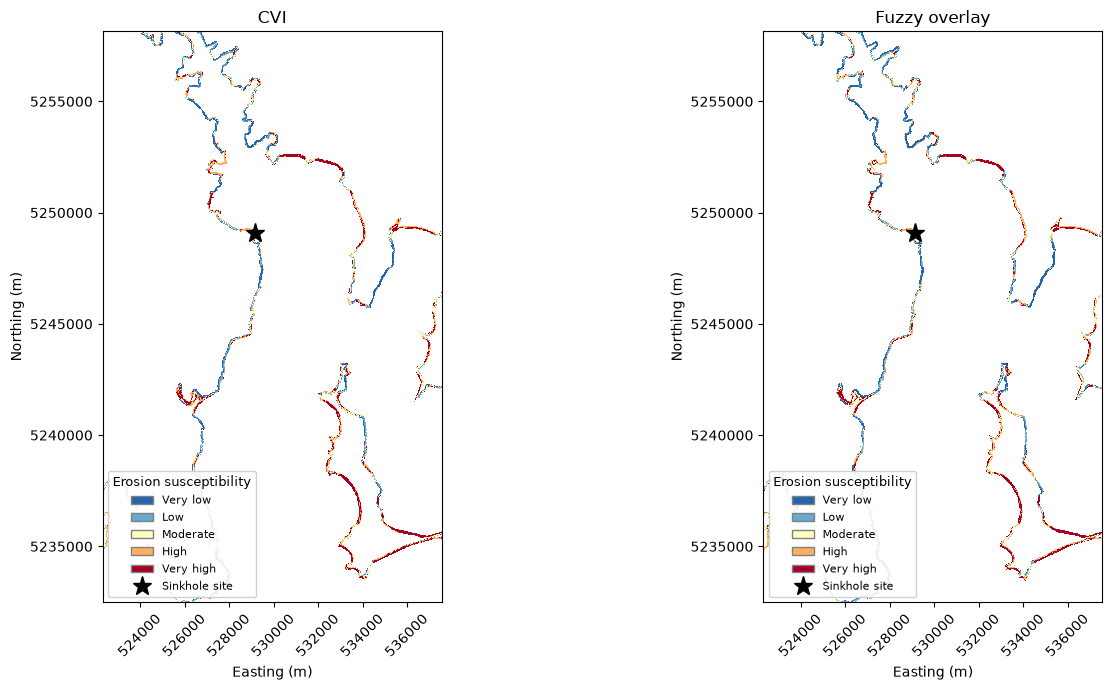

saved C:\AT3\outpath\map_zoom_both.png


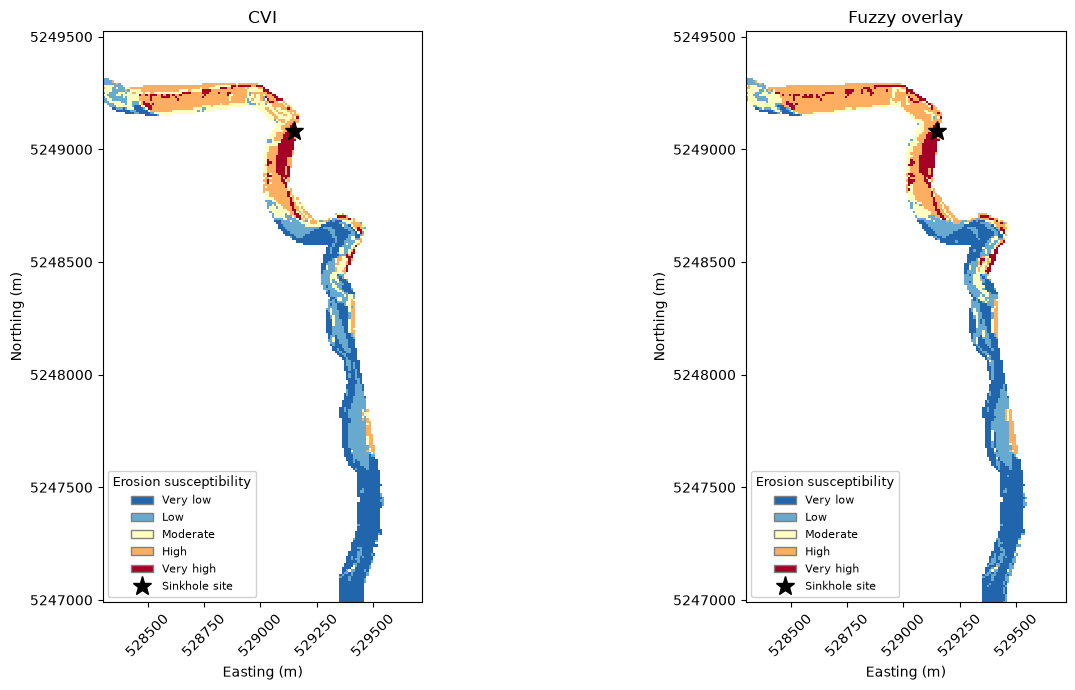

saved C:\AT3\outpath\map_cvi_full.png
saved C:\AT3\outpath\map_cvi_zoom.png
saved C:\AT3\outpath\map_fuzzy_full.png
saved C:\AT3\outpath\map_fuzzy_zoom.png
saved C:\AT3\outpath\map_surge_scenarios.png


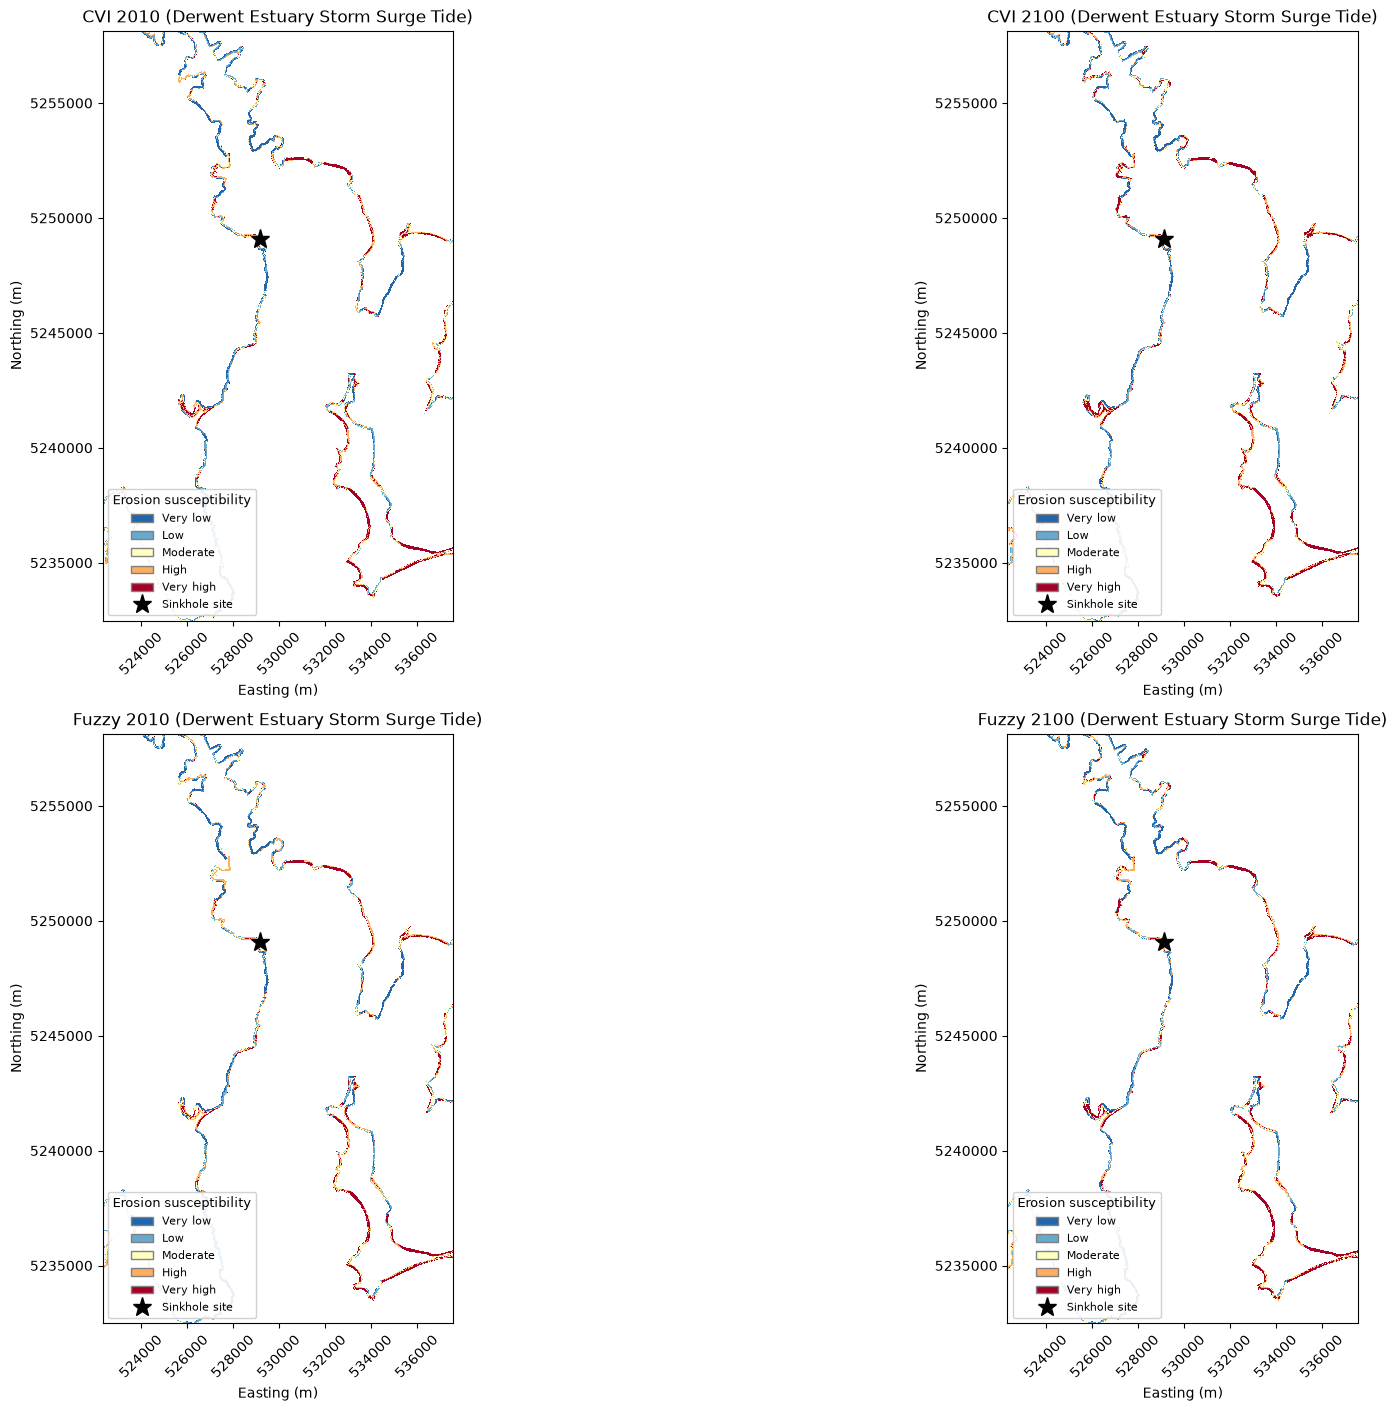

['CVI 2010', 'CVI 2100', 'Fuzzy 2010', 'Fuzzy 2100']
saved C:\AT3\outpath\map_surge_zoom_all.png


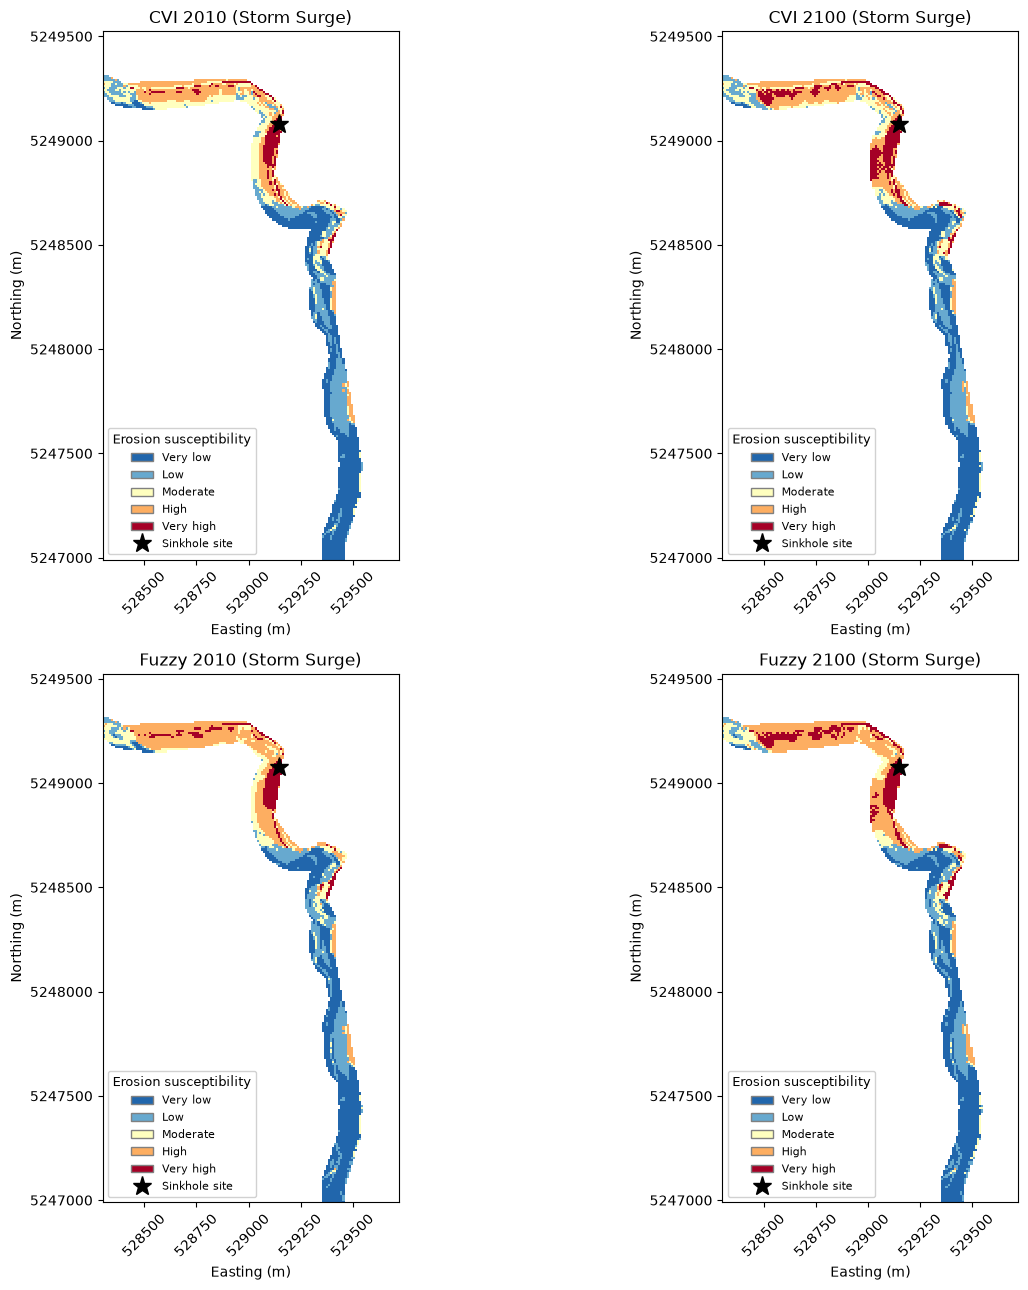

saved C:\AT3\outpath\map_surge_zoom_cvi_2010.png
saved C:\AT3\outpath\map_surge_zoom_cvi_2100.png
saved C:\AT3\outpath\map_surge_zoom_fuzzy_2010.png
saved C:\AT3\outpath\map_surge_zoom_fuzzy_2100.png


In [116]:
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap
from pyproj import Transformer

class_names = ["Very low", "Low", "Moderate", "High", "Very high"]      # EDIT: must have N entries
legend_handles = [Patch(facecolor=colours[i], edgecolor="grey", label=class_names[i]) for i in range(N)]

to_proj = Transformer.from_crs(4326, TARGET_CRS, always_xy=True)

def draw_map(ax, cls, title, xlim=None, ylim=None):
    ax.imshow(np.ma.masked_equal(cls, 0), extent=(minx, maxx, miny, maxy),
              cmap=ListedColormap(colours), vmin=1, vmax=N, interpolation="nearest")
    ax.set_title(title)
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")
    ax.ticklabel_format(style="plain", useOffset=False)
    ax.tick_params(axis="x", rotation=45)
    if xlim is not None:
        ax.set_xlim(xlim)
        ax.set_ylim(ylim)
    sx, sy = to_proj.transform(147.357093, -42.910343)
    ax.plot(sx, sy, marker="*", color="black", markersize=14, linestyle="none", label="Sinkhole site")
    ax.legend(handles=legend_handles + [ax.lines[-1]], title="Erosion susceptibility",
              loc="lower left", fontsize=8, title_fontsize=9, framealpha=0.9)

def save_fig(name):
    path = outpath / f"{name}.png"
    plt.savefig(path, dpi=200, bbox_inches="tight")
    print("saved", path)

models = [(cvi_cls, "CVI"), (fuzzy_cls, "Fuzzy overlay")]

# 1. whole study area: both models side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, (cls, name) in zip(axes, models):
    draw_map(ax, cls, f"{name}")
plt.tight_layout()
save_fig("map_full_both")
plt.show()

# 2. zoomed box: both models side by side
corners_latlon = [(-42.90637332, 147.34668207),
                  (-42.90719092, 147.36407658),
                  (-42.92914328, 147.36407956),
                  (-42.92601186, 147.34814428)]
cx, cy = zip(*[to_proj.transform(lon, lat) for lat, lon in corners_latlon])   # note lon first
zoom_x = (min(cx), max(cx))
zoom_y = (min(cy), max(cy))

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, (cls, name) in zip(axes, models):
    draw_map(ax, cls, f"{name}", zoom_x, zoom_y)
plt.tight_layout()
save_fig("map_zoom_both")
plt.show()

# 3. each model on its own, full and zoomed (handy for slides: one big map per slide)
for cls, name in models:
    tag = name.split()[0].lower()                      # "cvi" or "fuzzy"
    for suffix, xl, yl in [("full", None, None), ("zoom", zoom_x, zoom_y)]:
        fig, ax = plt.subplots(figsize=(8, 7))
        draw_map(ax, cls, f"{name}", xl, yl)
        plt.tight_layout()
        save_fig(f"map_{tag}_{suffix}")
        plt.close(fig)

if extra_cls:
    ncols = len(surge_folder)
    fig, axes = plt.subplots(2, ncols, figsize=(9 * ncols, 14), constrained_layout=True) 
    for ax, (name, cls) in zip(axes.ravel(), extra_cls.items()):
        draw_map(ax, cls, f"{name} (Derwent Estuary Storm Surge Tide)")
    save_fig("map_surge_scenarios")
    plt.show()

print(list(extra_cls.keys()))        # check the names: they become the panel titles

# 1. all scenario maps in one zoomed figure (2 columns: 2010 | 2100, rows = the models)
ncols = len(surge_folder)            # 2 scenarios
nrows = int(np.ceil(len(extra_cls) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 6.5 * nrows))
for ax, (name, cls) in zip(np.ravel(axes), extra_cls.items()):
    draw_map(ax, cls, f"{name} (Storm Surge)", zoom_x, zoom_y)
plt.tight_layout()
save_fig("map_surge_zoom_all")
plt.show()

# 2. each scenario map on its own, for the website / slides
for name, cls in extra_cls.items():
    fig, ax = plt.subplots(figsize=(8, 7))
    draw_map(ax, cls, f"{name} (Storm Surge)", zoom_x, zoom_y)
    plt.tight_layout()
    safe = name.lower().replace(" ", "_").replace("/", "_")      # file-name-safe version of the title
    save_fig(f"map_surge_zoom_{safe}")
    plt.close(fig)


CVI: change in class, 2010 to 2100 (147346 cells in both)
   +0: 132886 cells (90.2%)
   +1: 11482 cells (7.8%)
   +2: 2840 cells (1.9%)
   +3: 134 cells (0.1%)
   +4: 4 cells (0.0%)
   cells newly inside the zone in 2100: 0

Fuzzy: change in class, 2010 to 2100 (147346 cells in both)
   +0: 133645 cells (90.7%)
   +1: 11093 cells (7.5%)
   +2: 2546 cells (1.7%)
   +3: 62 cells (0.0%)
   cells newly inside the zone in 2100: 0
saved C:\AT3\outpath\map_change_2010_2100_full.png


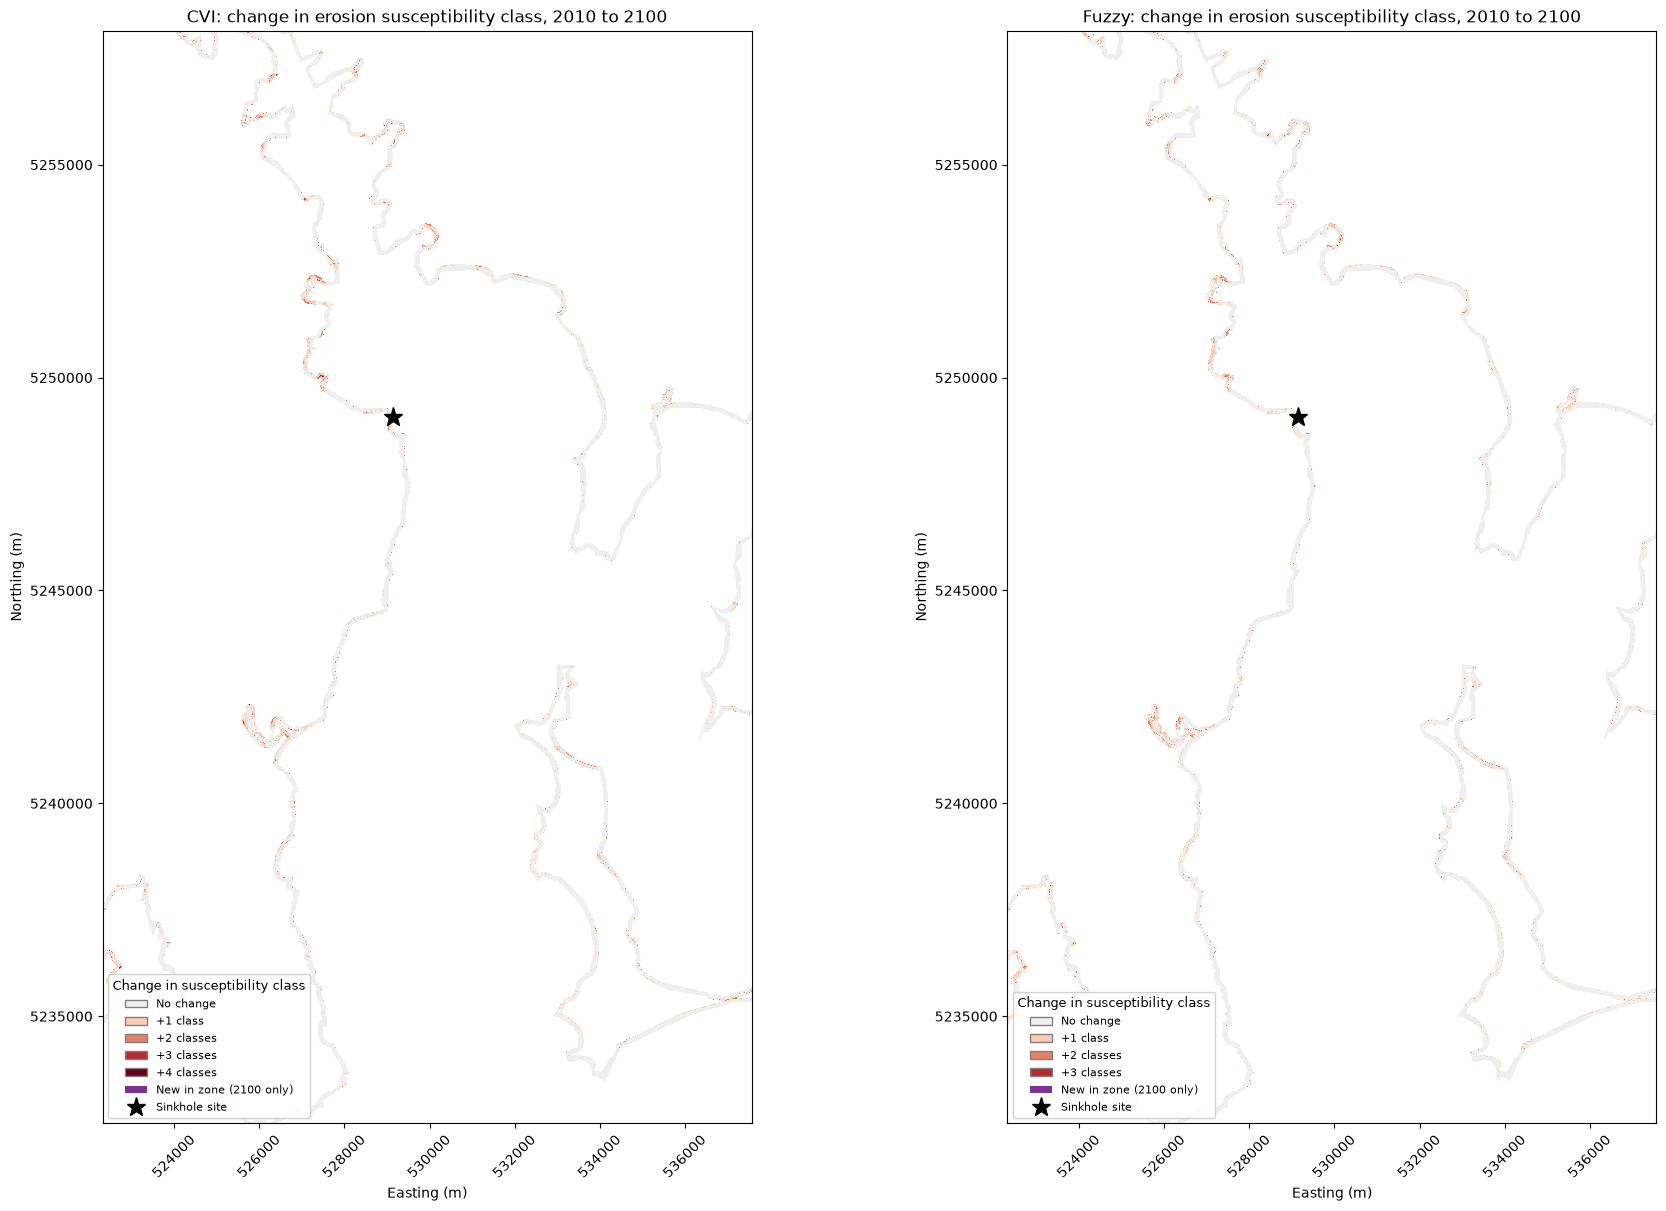

saved C:\AT3\outpath\map_change_2010_2100_zoom.png


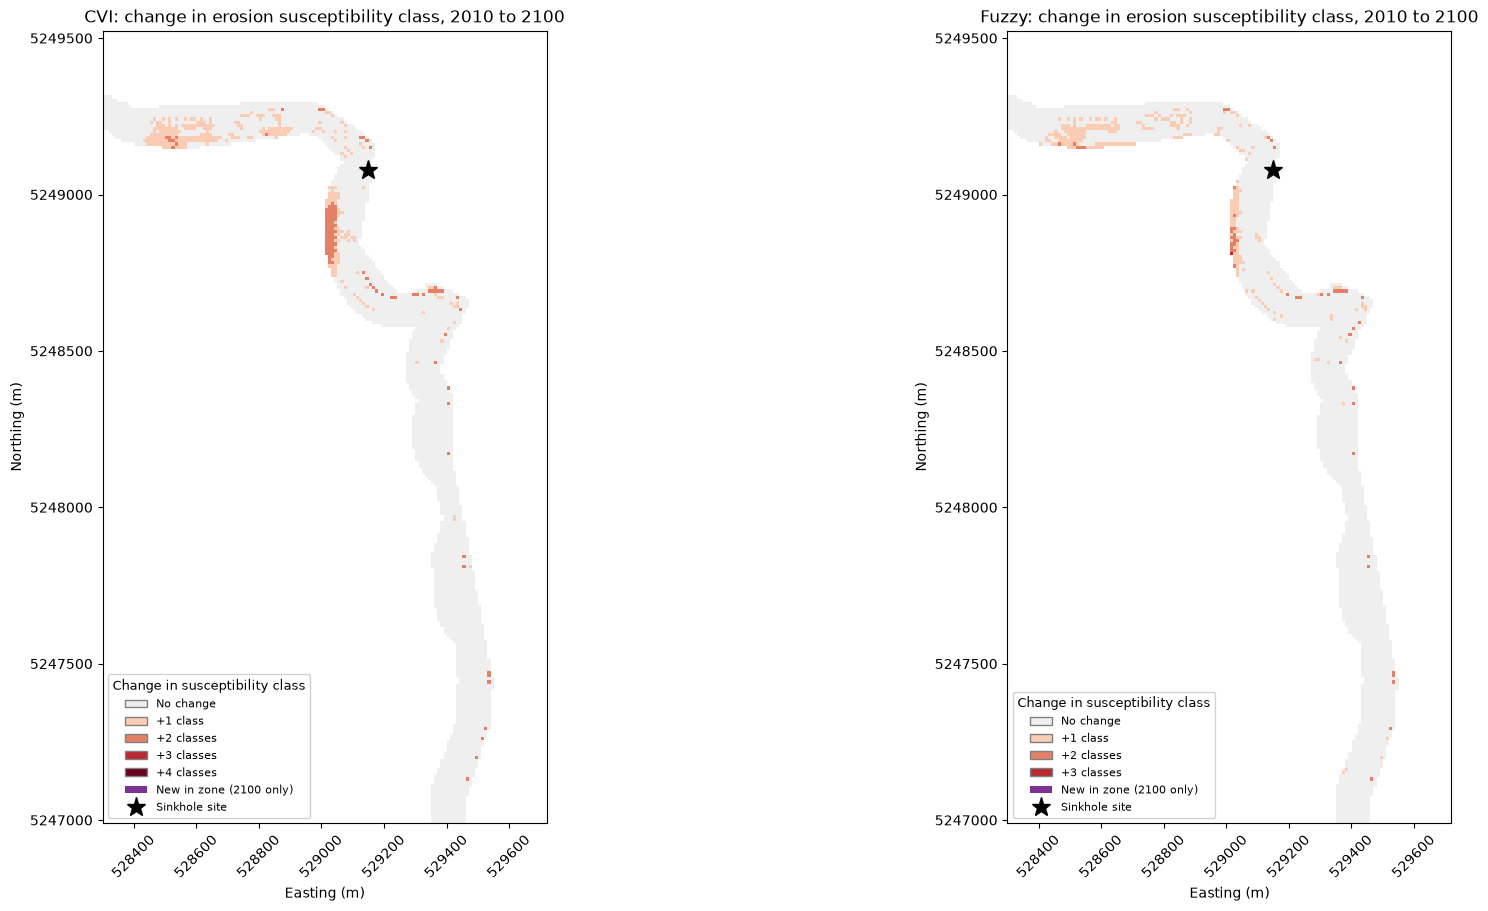

CVI cells changed class: 14460
Fuzzy cells changed class: 13701
saved C:\AT3\outpath\map_change_zoomed_changed_cells.png


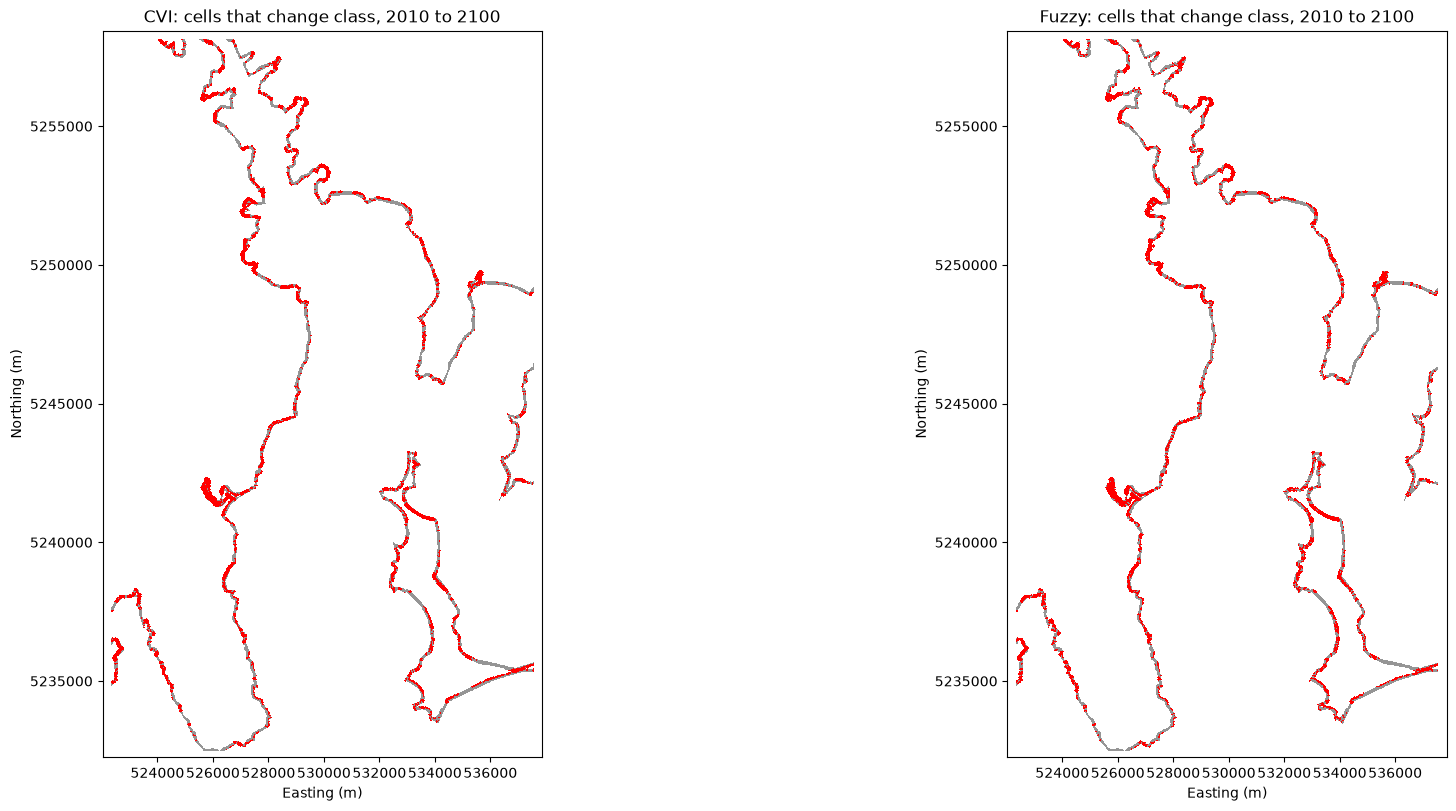

In [120]:
# restore the grid coordinates (an earlier cell reused the names xs / ys for the zoom-box corners)
minx, miny, maxx, maxy = bounds
xs = np.arange(minx + GRID_RES / 2, maxx, GRID_RES)
ys = np.arange(maxy - GRID_RES / 2, miny, -GRID_RES)
assert len(ys) == fetch_grid.shape[0] and len(xs) == fetch_grid.shape[1], "grid coordinates don't match the grid"

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# ---- 1. class change, 2100 minus 2010, per model ----
change_map = {}
new_in_zone = {}
for model in ["CVI", "Fuzzy"]:
    a = extra_cls[f"{model} 2010"].astype(int)
    b = extra_cls[f"{model} 2100"].astype(int)
    both = (a > 0) & (b > 0)                                  # cell is analysed in both scenarios
    change_map[model] = np.where(both, b - a, np.nan)         # +1 = moved up one class
    new_in_zone[model] = (a == 0) & (b > 0)                   # only inside the zone in 2100 (new flood margin)
    to_da(change_map[model]).rio.to_raster(outpath / f"{model}_change_2010_to_2100.tif")

    vals, counts = np.unique(change_map[model][both], return_counts=True)
    print(f"\n{model}: change in class, 2010 to 2100 ({int(both.sum())} cells in both)")
    for v, n in zip(vals.astype(int), counts):
        print(f"   {v:+d}: {n} cells ({n / both.sum() * 100:.1f}%)")
    print(f"   cells newly inside the zone in 2100: {int(new_in_zone[model].sum())}")

# ---- 2. colours: grey = no change, blue = decrease, red = increase ----
levels = np.arange(-4, 5)                                     # -4 ... +4
palette = list(plt.get_cmap("RdBu_r")(np.linspace(0, 1, len(levels))))
palette[4] = (0.94, 0.94, 0.94, 1.0)                          # 0 = light grey
change_cmap = ListedColormap(palette)
change_norm = BoundaryNorm(np.arange(-4.5, 5.5, 1), len(levels))
NEW_COLOUR = "#7b3294"

def draw_change(ax, model, title, xlim=None, ylim=None):
    ch = change_map[model]
    ax.imshow(np.ma.masked_invalid(ch), extent=(minx, maxx, miny, maxy),
              cmap=change_cmap, norm=change_norm, interpolation="nearest")
    ax.imshow(np.ma.masked_equal(new_in_zone[model].astype(int), 0), extent=(minx, maxx, miny, maxy),
              cmap=ListedColormap([NEW_COLOUR]), interpolation="nearest")
    ax.set_title(title)
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")
    ax.ticklabel_format(style="plain", useOffset=False)
    ax.tick_params(axis="x", rotation=45)
    if xlim is not None:
        ax.set_xlim(xlim)
        ax.set_ylim(ylim)
    sx, sy = to_proj.transform(147.357093, -42.910343)
    star, = ax.plot(sx, sy, marker="*", color="black", markersize=14, linestyle="none", label="Sinkhole site")
    present = sorted(set(np.unique(ch[np.isfinite(ch)]).astype(int)) | {0})
    handles = [Patch(facecolor=palette[v + 4], edgecolor="grey",
                     label="No change" if v == 0 else f"{v:+d} class{'es' if abs(v) > 1 else ''}") for v in present]
    handles.append(Patch(facecolor=NEW_COLOUR, label="New in zone (2100 only)"))
    ax.legend(handles=handles + [star], title="Change in susceptibility class", loc="lower left",
              fontsize=8, title_fontsize=9, framealpha=0.9)

# ---- 3. maps: whole area and zoomed, CVI and fuzzy ----
for view, xl, yl, size in [("full", None, None, (18, 12)), ("zoom", zoom_x, zoom_y, (18, 9))]:
    fig, axes = plt.subplots(1, 2, figsize=size, constrained_layout=True)
    for ax, model in zip(axes, ["CVI", "Fuzzy"]):
        draw_change(ax, model, f"{model}: change in erosion susceptibility class, 2010 to 2100", xl, yl)
    save_fig(f"map_change_2010_2100_{view}")
    plt.show()

from scipy.ndimage import binary_dilation

minx, miny, maxx, maxy = bounds
GROW = 3      # EDIT: enlarge changed cells by this many cells so they are visible (0 = true size)
PAD = 300     # EDIT: metres of padding around the changed cells

fig, axes = plt.subplots(1, 2, figsize=(18, 8), constrained_layout=True)

for ax, model in zip(axes, ["CVI", "Fuzzy"]):
    a = extra_cls[f"{model} 2010"].astype(int)
    b = extra_cls[f"{model} 2100"].astype(int)
    changed = (a > 0) & (b > 0) & (a != b)
    print(model, "cells changed class:", int(changed.sum()))

    # grey background = the 2100 zone
    ax.imshow(np.where(b > 0, 1.0, np.nan), extent=(minx, maxx, miny, maxy),
              cmap="Greys", vmin=0, vmax=2, interpolation="nearest")

    # changed cells, enlarged so they show up
    show = binary_dilation(changed, iterations=GROW) if GROW > 0 else changed
    ax.imshow(np.where(show, 1.0, np.nan), extent=(minx, maxx, miny, maxy),
              cmap="autumn_r", vmin=0, vmax=1, interpolation="nearest")

    # crop to the changed cells
    if changed.any():
        rows, cols = np.where(changed)
        ax.set_xlim(xs[cols.min()] - PAD, xs[cols.max()] + PAD)
        ax.set_ylim(ys[rows.max()] - PAD, ys[rows.min()] + PAD)

    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")
    ax.set_title(f"{model}: cells that change class, 2010 to 2100")
    ax.ticklabel_format(style="plain", useOffset=False)

save_fig("map_change_zoomed_changed_cells")
plt.show()

In [112]:
# interactive map (demonstrate this in class; leafmap output does not export)
m = leafmap.Map(center=[site.y, site.x], zoom=10)
m.add_basemap("SATELLITE")

for name, file in {"CVI": "CVI_Classified.tif", "Fuzzy overlay": "Fuzzy_Classified.tif"}.items():
    m.add_raster(str(outpath / file), colormap=colours, vmin=1, vmax=N, nodata=0,
                 layer_name=f"{name} susceptibility")

# the optional per-scenario layers start switched off; turn them on in the layer manager
for name in extra_cls:
    model, yr = name.split()
    m.add_raster(str(outpath / f"{model}_{yr}_Classified.tif"), colormap=colours, vmin=1, vmax=N, nodata=0,
                 layer_name=f"{name} surge only", visible=False)

m.add_vector(str(outpath / "coastline.gpkg"), layer_name="Coastline")

m.add_legend(title="Erosion Susceptibility", labels=class_names, colors=colours)
m.add_text(
    text=("<b>Data Sources:</b><br>"
          "DEM - ELVIS<br>"
          "Geology - MRT Tasmania<br>"
          "Coastline - LISTdata<br>"
          "Shoreline change - DEA Coastlines<br>"
          "Wind - ERA5"),
    fontsize=13, fontcolor="black", padding="8px", background=True, bg_color="white",
    border_radius="5px", position="bottomleft",
)
m.add_layer_manager()
m

Map(center=[-42.9441465, 147.3671595], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_tit…